In [1]:
import urllib.request, numpy as np, pandas as pd, matplotlib.pyplot as plt, re
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
urllib.request.urlretrieve(URL, "sms.tsv")
df = pd.read_csv("sms.tsv", sep="\t", header=None, names=["label", "text"])
df["y"] = (df.label == "spam").astype(int)
print(df.shape)
print(df.label.value_counts())
df.sample(5, random_state=1)

(5572, 3)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text,y
1078,ham,"Yep, by the pretty sculpture",0
4028,ham,"Yes, princess. Are you going to make me moan?",0
958,ham,Welp apparently he retired,0
4642,ham,Havent.,0
4674,ham,I forgot 2 ask ü all smth.. There's a card on ...,0


## 1. Explore the data

       length  n_digits
label                  
ham      71.5       0.3
spam    138.7      15.8


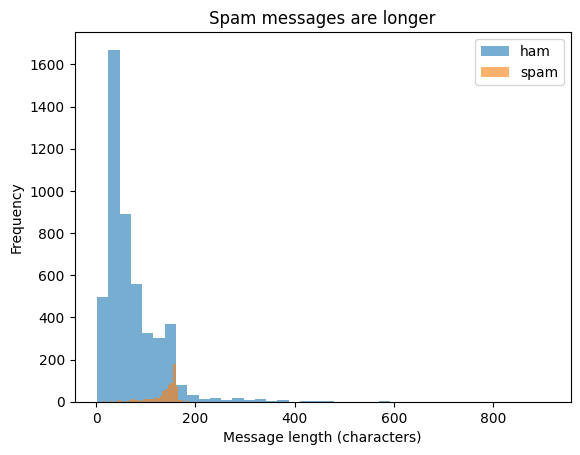

In [2]:
df["length"] = df.text.str.len()
df["n_digits"] = df.text.str.count(r"\d")
print(df.groupby("label")[["length", "n_digits"]].mean().round(1))

df.groupby("label").length.plot(kind="hist", bins=40, alpha=0.6, legend=True)
plt.xlabel("Message length (characters)"); plt.title("Spam messages are longer"); plt.show()

## 2. Clean text and split
Stratified split keeps the spam ratio (about 13%) the same in train and test.

In [3]:
def clean(t):
    t = t.lower()
    t = re.sub(r"\d+", " num ", t)        # replace numbers
    t = re.sub(r"[^a-z\s]", " ", t)       # remove punctuation
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df.text.apply(clean)
X_train, X_test, y_train, y_test = train_test_split(
    df.clean, df.y, test_size=0.2, stratify=df.y, random_state=42)
print(len(X_train), len(X_test), "| spam share:", round(y_train.mean(), 3), round(y_test.mean(), 3))

4457 1115 | spam share: 0.134 0.134


## 3. Train and compare models
TF-IDF (unigrams + bigrams) with three classifiers. Cross-validation uses the training set only.

In [4]:
def make(clf):
    return Pipeline([("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                     ("clf", clf)])

models = {"Naive Bayes": make(MultinomialNB(alpha=0.1)),
          "Logistic Regression": make(LogisticRegression(max_iter=1000, class_weight="balanced")),
          "Linear SVM": make(LinearSVC(C=0.5, class_weight="balanced"))}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    cv_f1 = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1").mean()
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({"Model": name, "CV F1": round(cv_f1, 4),
                 "Test Accuracy": round(accuracy_score(y_test, p), 4),
                 "Test Precision": round(precision_score(y_test, p), 4),
                 "Test Recall": round(recall_score(y_test, p), 4),
                 "Test F1": round(f1_score(y_test, p), 4)})
results = pd.DataFrame(rows)
results

,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Naive Bayes,0.9561,0.9857,0.9784,0.9128,0.9444
1,Logistic Regression,0.8970,0.9794,0.8987,0.9530,0.9251
2,Linear SVM,0.9334,0.9865,0.9527,0.9463,0.9495


## 4. Best model: detailed evaluation

Best model: Linear SVM
              precision    recall  f1-score   support

         ham      0.992     0.993     0.992       966
        spam      0.953     0.946     0.949       149

    accuracy                          0.987      1115
   macro avg      0.972     0.970     0.971      1115
weighted avg      0.987     0.987     0.987      1115



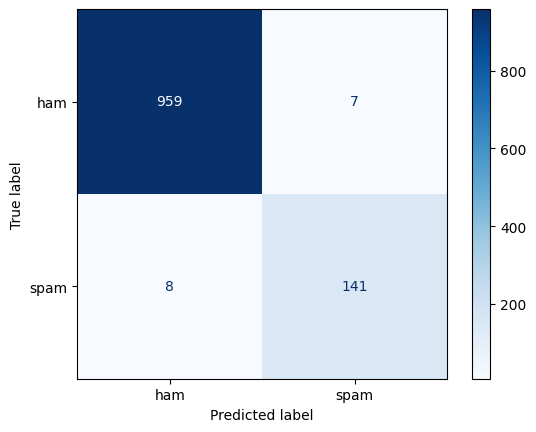

In [5]:
best_name = results.sort_values("Test F1", ascending=False).iloc[0].Model
best = models[best_name]
p = best.predict(X_test)
print("Best model:", best_name)
print(classification_report(y_test, p, target_names=["ham", "spam"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=["ham", "spam"], cmap="Blues")
plt.show()

## 5. What words signal spam?

In [6]:
lr = models["Logistic Regression"]
vec, clf = lr.named_steps["tfidf"], lr.named_steps["clf"]
words = np.array(vec.get_feature_names_out())
order = np.argsort(clf.coef_[0])
print("Top spam words:", list(words[order[-15:]][::-1]))
print("Top ham words :", list(words[order[:15]]))

Top spam words: ['num', 'num num', 'txt', 'uk', 'mobile', 'reply', 'free', 'www', 'text', 'claim', 'com', 'stop', 'service', 'sms', 'new']
Top ham words : ['ok', 'got', 'll', 'hey', 'lt', 'home', 'lor', 'gt', 'good', 'da', 'come', 'lt gt', 'sorry', 'later', 'work']


## 6. Misclassified messages and live predictions

In [7]:
wrong = X_test[p != y_test]
print("Misclassified:", len(wrong), "of", len(X_test))
display(df.loc[wrong.index, ["label", "text"]].head(8))

def predict(msg):
    return "SPAM" if best.predict([clean(msg)])[0] == 1 else "HAM"

for m in ["Congratulations! You won a free prize. Call 09061701461 now to claim",
          "Hey, are we still meeting for lunch tomorrow?",
          "URGENT! Your account is locked. Text STOP to 80082 to claim a reward"]:
    print(predict(m), "<-", m)

Misclassified: 15 of 1115


,label,text
3247,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t..."
1703,ham,I have lost 10 kilos as of today!
3360,spam,Sorry I missed your call let's talk when you h...
5449,spam,"Latest News! Police station toilet stolen, cop..."
5359,ham,This is ur face test ( 1 2 3 4 5 6 7 8 9 &lt;...
5484,ham,", , and picking them up from various points ..."
1430,spam,For sale - arsenal dartboard. Good condition b...
1451,ham,Msg me when rajini comes.


SPAM <- Congratulations! You won a free prize. Call 09061701461 now to claim
HAM <- Hey, are we still meeting for lunch tomorrow?
SPAM <- URGENT! Your account is locked. Text STOP to 80082 to claim a reward
